# FINM36700-Portfolio and Risk Management

## Chapter 1: Risk and Return

### 1.1 Risk and Return Metrics

In [1]:
import pandas as pd
import numpy as np
import datetime
import warnings
import matplotlib.pyplot as plt

from portfolio import *

from matplotlib.ticker import (MultipleLocator,
                               FormatStrFormatter,
                               AutoMinorLocator)
from sklearn.linear_model import LinearRegression
from scipy.optimize import minimize

#### Example: ETF Data

In [2]:
LOADFILE = 'data/risk_etf_data.xlsx'

# Information about the ETFs
info = pd.read_excel(LOADFILE,sheet_name='descriptions').set_index('ticker')
# Load the returns and prices data
rets = pd.read_excel(LOADFILE,sheet_name='total returns').set_index('Date')
prices = pd.read_excel(LOADFILE,sheet_name='prices').set_index('Date')

# Define the trading frequency
FREQ = 252

In [3]:
# Display info of the ETFs
info

,quoteType,shortName,volume,totalAssets,longBusinessSummary
ticker,,,,,
SPY,ETF,SPDR S&P 500,91993247,6.035170e+11,The trust seeks to achieve its investment obje...
VEA,ETF,Vanguard FTSE Developed Markets,14117842,2.247459e+11,The fund employs an indexing investment approa...
UPRO,ETF,ProShares UltraPro S&P 500,3575899,3.852897e+09,The fund invests in financial instruments that...
GLD,ETF,SPDR Gold Trust,8046469,9.798884e+10,The Trust holds gold bars and from time to tim...
USO,ETF,United States Oil Fund,5910069,9.070093e+08,USO invests primarily in futures contracts for...
FXE,ETF,Invesco CurrencyShares Euro Cur,195591,5.239969e+08,NaN
BTC-USD,CRYPTOCURRENCY,Bitcoin USD,41706745856,NaN,NaN
HYG,ETF,iShares iBoxx $ High Yield Corp,49277832,1.594403e+10,The underlying index is a rules-based index co...
IEF,ETF,iShares 7-10 Year Treasury Bond,10542291,3.493820e+10,The underlying index measures the performance ...


In [4]:
# Peek at the returns data
rets.tail().style.format('{:.1%}').format_index('{:%Y-%m-%d}')

,SPY,VEA,UPRO,GLD,USO,FXE,BTC,HYG,IEF,TIP,SHV
Date,,,,,,,,,,,
2025-06-23,1.0%,0.8%,3.0%,0.3%,-8.1%,0.6%,2.2%,0.2%,0.3%,0.1%,0.0%
2025-06-24,1.1%,1.3%,3.3%,-1.6%,-4.5%,0.3%,0.4%,0.3%,0.3%,0.1%,0.0%
2025-06-25,0.1%,-0.5%,0.2%,0.3%,0.4%,0.4%,1.2%,-0.0%,0.0%,0.1%,0.0%
2025-06-26,0.8%,1.1%,2.3%,-0.1%,0.4%,0.4%,-0.4%,0.3%,0.4%,0.3%,0.0%
2025-06-27,0.5%,0.6%,1.3%,-1.8%,-0.4%,0.0%,0.1%,-0.0%,-0.3%,-0.1%,0.0%


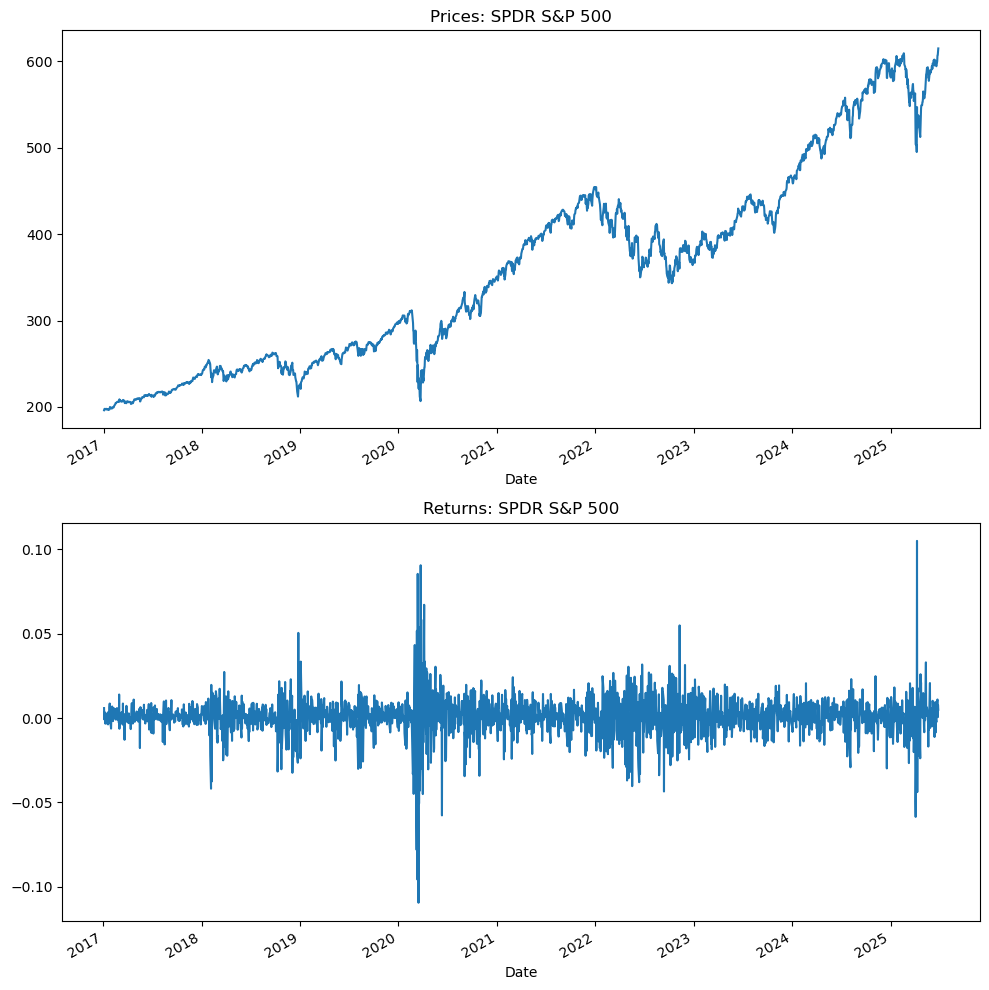

In [5]:
# Plot time series of prices and returns
TICK = 'SPY'
fig, ax = plt.subplots(2,1,figsize=(10,10))
desc = info.loc[TICK,'shortName'] # get the description, i.e. the shortName column in info
prices[TICK].plot(ax=ax[0],title=f'Prices: {desc}')
rets[TICK].plot(ax=ax[1],title=f'Returns: {desc}')
plt.tight_layout()
plt.show()

In [6]:
# Calculate risk and return metrics
mets = performanceMetrics(rets,annualization=FREQ) # imported from portfolio.py
mets['skewness'] = rets.skew()
mets['kurtosis'] = rets.kurtosis()
mets['max drawdown'] = maximumDrawdown(rets)['Max Drawdown']
mets.style.format('{:.1%}')

,Mean,Vol,Sharpe,Min,Max,skewness,kurtosis,max drawdown
SPY,15.3%,18.9%,81.1%,-10.9%,10.5%,-30.5%,1424.1%,-33.7%
VEA,9.7%,17.5%,55.4%,-11.2%,8.9%,-86.0%,1612.0%,-35.7%
UPRO,38.8%,56.5%,68.8%,-34.9%,28.0%,-38.1%,1498.6%,-76.8%
GLD,12.9%,14.3%,90.2%,-5.4%,4.9%,-15.0%,270.0%,-22.0%
USO,5.0%,38.6%,13.0%,-25.3%,16.7%,-127.6%,1630.1%,-86.8%
FXE,1.6%,7.4%,21.7%,-2.1%,2.5%,16.3%,134.9%,-26.5%
BTC,79.3%,69.8%,113.5%,-37.2%,25.2%,2.7%,615.5%,-83.0%
HYG,4.6%,8.7%,53.6%,-5.5%,6.5%,13.0%,2642.3%,-22.0%
IEF,1.3%,6.9%,18.3%,-2.5%,2.6%,19.7%,319.6%,-23.9%
TIP,2.8%,6.0%,45.8%,-2.9%,4.5%,36.3%,1485.6%,-14.5%


#### Maximum Drawdown - ETF Data

| Column                    | Meaning                                                  |
| :------------------------ | :------------------------------------------------------- |
| **Max Drawdown**          | The largest loss from a previous peak                    |
| **Peak**                  | Date of the portfolio’s highest value before the drop    |
| **Bottom**                | Date when the lowest point occurred                      |
| **Recover**               | Date when the portfolio fully regained its previous high |
| **Duration (to Recover)** | Time from the peak to full recovery                      |

**Recover** means the first date ***after the bottom*** when the portfolio fully recovers back to its previous high (i.e., drawdown ≥ 0). If the portfolio never gets back to that peak, this part fails and is set to `None`.

In [7]:
maximumDrawdown(rets).sort_values('Max Drawdown').style.format({
    'Skewness': '{:.2f}',
    'Kurtosis': '{:.2f}', 
    'Max Drawdown': '{:.2%}',
    'Peak': lambda x: x.strftime('%Y-%m-%d') if pd.notna(x) else '',
    'Bottom': lambda x: x.strftime('%Y-%m-%d') if pd.notna(x) else '',
    'Recover': lambda x: x.strftime('%Y-%m-%d') if pd.notna(x) else '',
    'Duration (to Recover)': lambda x: f'{x.days:,.0f} days' if pd.notna(x) else ''
})

,Max Drawdown,Peak,Bottom,Recover,Duration (to Recover)
USO,-86.75%,2018-10-03,2020-04-28,,
BTC,-83.04%,2017-12-18,2018-12-14,2020-11-30,"1,078 days"
UPRO,-76.82%,2020-02-19,2020-03-23,2021-01-08,324 days
VEA,-35.74%,2018-01-26,2020-03-23,2020-11-16,"1,025 days"
SPY,-33.72%,2020-02-19,2020-03-23,2020-08-10,173 days
FXE,-26.46%,2018-02-01,2022-09-27,,
IEF,-23.92%,2020-08-04,2023-10-19,,
HYG,-22.03%,2020-02-20,2020-03-23,2020-11-04,258 days
GLD,-22.00%,2020-08-06,2022-09-26,2024-03-04,"1,306 days"
TIP,-14.51%,2021-11-09,2023-10-06,,


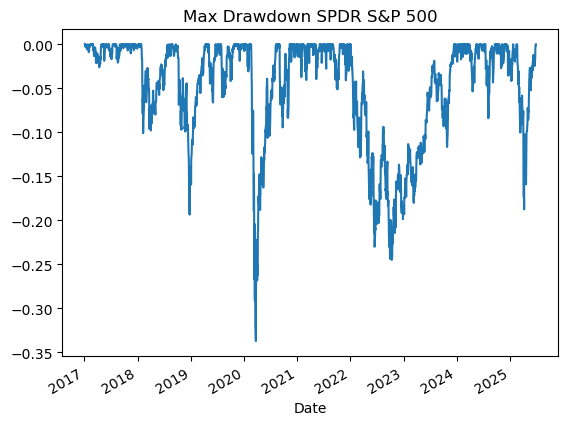

In [8]:
# Plot time series of maximum drawdown for a specific ETF
TICK = 'SPY'
desc = info.loc[TICK,'shortName'] # get the description, i.e. the shortName column in info
drawdown = mdd_timeseries(rets)
drawdown[TICK].plot(title=f'Max Drawdown {desc}');
plt.show()

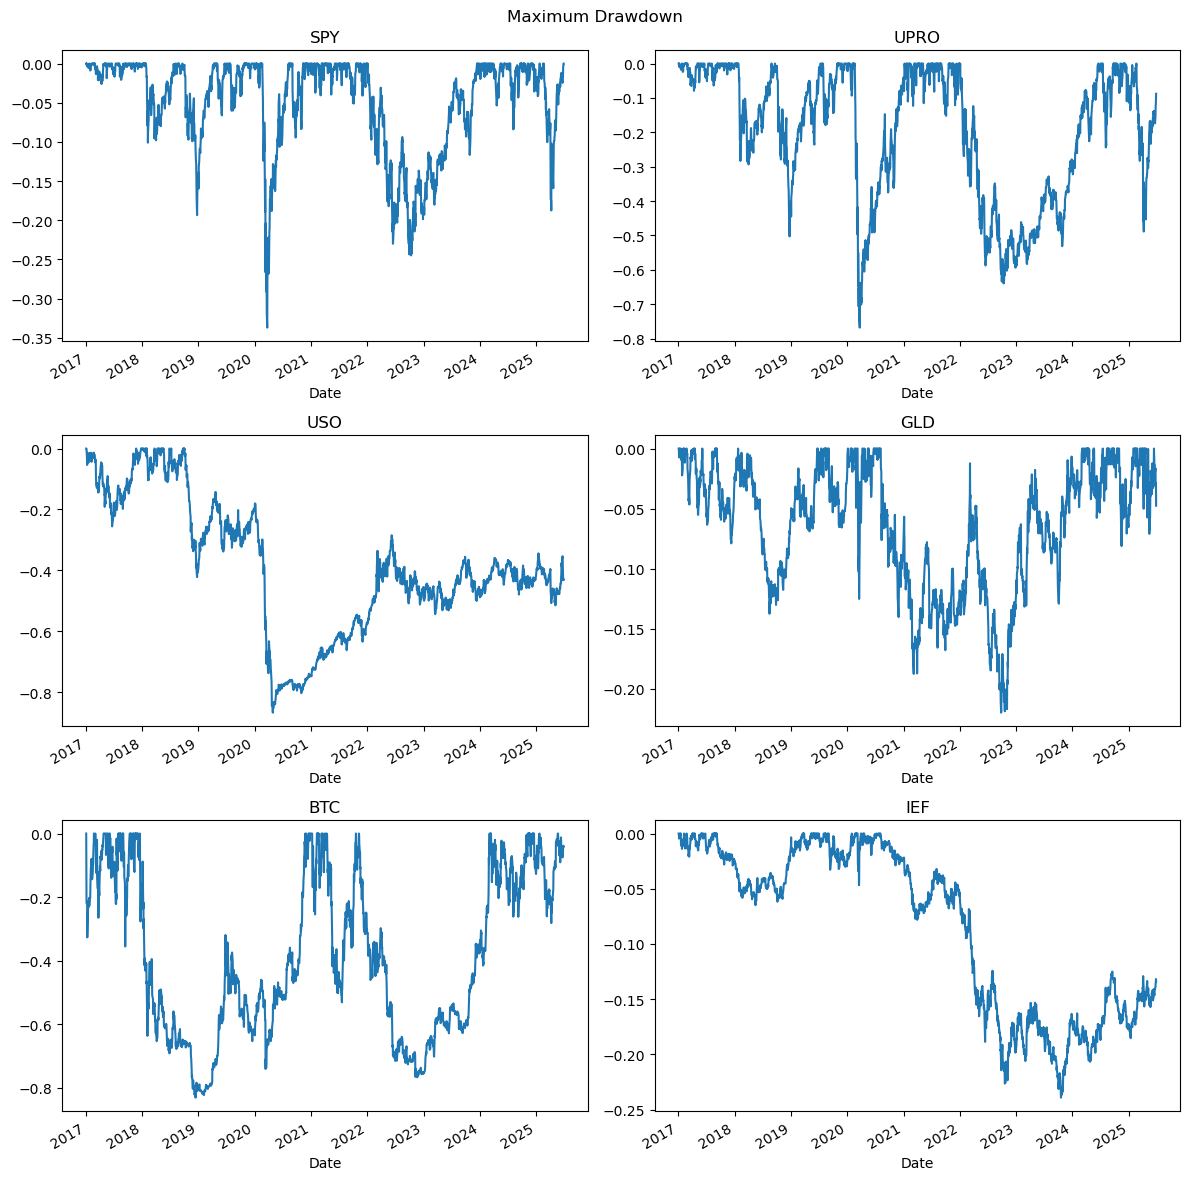

In [9]:
# Plot time series of maximum drawdown for multiple ETFs
PLOT_TICKS = ['SPY','UPRO','USO','GLD','BTC','IEF']
n_plots = len(PLOT_TICKS)
n_rows = int(np.ceil(n_plots/2))
fig, ax = plt.subplots(n_rows, 2, figsize=(12, 4*n_rows))
ax = ax.flatten()

for i, tick in enumerate(PLOT_TICKS):
    drawdown[tick].plot(ax=ax[i], title=tick)

plt.suptitle('Maximum Drawdown')
plt.tight_layout()
plt.show()

#### Correlation Matrix - ETF Data

Max corr (within shown triangle): ('SPY', 'UPRO', 0.9988919611728845)
Min corr (within shown triangle): ('USO', 'IEF', -0.14947893460971096)


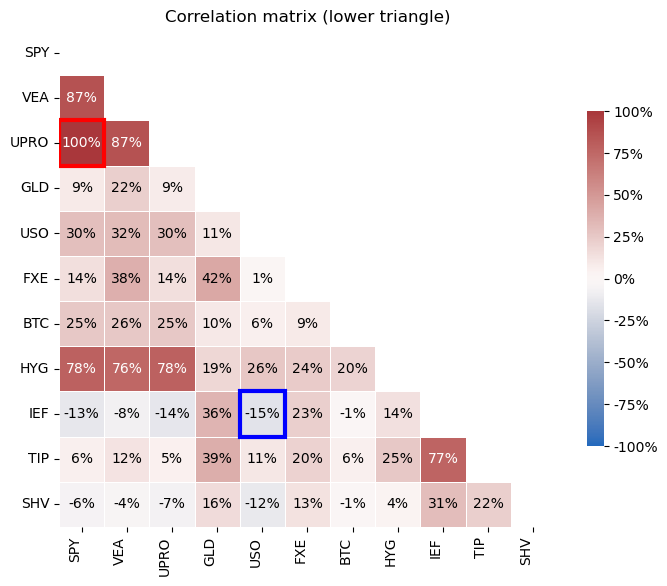

In [10]:
# Plot correlation matrix and show max/min correlations
fig, ax, extremes = plot_corr_matrix_classic(rets, triangle='lower', figsize=(7,7))
print('Max corr (within shown triangle):', extremes['max'])
print('Min corr (within shown triangle):', extremes['min'])

### 1.2 Optimizating Risk and Return

Many performance measures, as well as optimizations, will focus on excess returns. That is, the return on the portfolio / security beyond the risk-free rate.

We use tilde notation for excess returns to avoid writing the risk-free rate everywhere. That is,

$$
\begin{aligned}
\tilde{r}_{i, t} & \equiv r_{i, t}-r_f \\
\tilde{\mu} & \equiv \mu-r_f
\end{aligned}
$$

Consider a regression of the portfolio (or security) return against a benchmark, in this case, SPY.

$$
\tilde{r}_{i, t}=\alpha+\beta \tilde{r}_{\mathrm{SPY}, t}+\epsilon_t
$$


Note that we might be interested in a decomposition against several factors, $\boldsymbol{x}_t$.

$$
\tilde{r}_{i, t}=\alpha+\boldsymbol{\beta}^{\prime} \boldsymbol{x}_t+\epsilon_t
$$


We will have more to say about these decompositions.

In [11]:
doEXCESS = True
COMP = 'SPY' # market benchmark


if doEXCESS:
    data = rets
else:
    data = rets
    
    
regs = pd.DataFrame(dtype=float, columns=['mean','alpha','beta'], index=rets.columns)
for sec in rets.columns:
    est = LinearRegression().fit(data[[COMP]],data[[sec]])
    regs.loc[sec,'alpha'] = est.intercept_
    regs.loc[sec,'beta'] = est.coef_[0]

regs['mean'] = rets.mean()
regs[['mean','alpha']] *= FREQ
regs.style.format({'mean':'{:.2%}','alpha':'{:.2%}','beta':'{:.2f}'})

,mean,alpha,beta
SPY,15.29%,0.00%,1.00
VEA,9.70%,-2.58%,0.80
UPRO,38.85%,-6.93%,2.99
GLD,12.88%,11.88%,0.07
USO,5.02%,-4.41%,0.62
FXE,1.60%,0.75%,0.06
BTC,79.29%,65.08%,0.93
HYG,4.65%,-0.86%,0.36
IEF,1.26%,1.99%,-0.05
TIP,2.76%,2.47%,0.02


The **Sharpe ratio** is the tradeoff of **mean excess return** against **volatility**. 

$$
\text { Sharpe Ratio } \equiv \frac{\tilde{\mu}}{\tilde{\sigma}}
$$


In some cases this measure is used for total returns, not excess:

$$
\text { Sharpe Ratio } \equiv \frac{\mu}{\sigma}
$$

The **Treynor ratio** is the tradeoff between **mean excess return** and **beta**.

This is mostly used with equities, where the beta is with regard to a broad equity benchmark, like SPY.

$$
\text { Treynor Ratio } \equiv \frac{\tilde{\mu}}{\beta}
$$

The **Information Ratio** is the tradeoff between **alpha** and **unexplained volatility** (based on a benchmark).

A regression of $\tilde{r}_{i, t}$ onto a factor (benchmark) $x_t$ reveals the unexplained...
- mean: $\alpha$
- movements: $\epsilon$
- volatility: $\sigma_\epsilon$ as well as the explained portion, $\beta x$.

The Information Ratio is thus the Sharpe ratio of the unexplained portion of the decomposition, $\alpha$ versus $\epsilon$.

$$
\text { Information Ratio } \equiv \frac{\alpha}{\sigma_\epsilon}
$$

In [12]:
keyX = 'SPY'
tab = pd.concat([performanceMetrics(rets,annualization=FREQ)['Sharpe'],
                 get_ols_metrics(rets[keyX],rets,annualization=FREQ)[['Info Ratio','Treynor Ratio']]],
                 axis=1)
tab.fillna(np.nan,inplace=True)
tab.style.format({'alpha':'{:.2%}','Sharpe':'{:.2%}','r-squared':'{:.2%}','Treynor Ratio':'{:.2%}','Info Ratio':'{:.2%}'})

/var/folders/vf/ml0jt6z91qsdhgg6jwg8p76h0000gn/T/ipykernel_34419/1860396206.py:5: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  tab.fillna(np.nan,inplace=True)


,Sharpe,Info Ratio,Treynor Ratio
SPY,81.12%,nan%,15.29%
VEA,55.42%,-29.43%,12.08%
UPRO,68.76%,-260.76%,12.98%
GLD,90.21%,83.50%,196.33%
USO,13.00%,-11.98%,8.14%
FXE,21.69%,10.30%,28.86%
BTC,113.55%,96.27%,85.30%
HYG,53.55%,-15.79%,12.92%
IEF,18.30%,29.22%,-26.23%
TIP,45.84%,41.08%,144.94%


### 1.3 Mean-Variance Optimization

#### 1.3.1 Variance of a Portfolio

Consider a portfolio of $K$ risky securities.
- return volatility is $\sigma_i$
- return covariance is $\sigma_{i, j}$
- weight in security $i$ is given by $w_i$, with $\$ \sum_{i=1}^K w_i=1 \$$

Then

$$
\sigma_p^2=\sum_{j=1}^K \sum_{i=1}^K w_i w_j \sigma_{i j}
$$


Suppose we have an equally-weighted portfolio, $w_i=\frac{1}{K}$ for all $i$.
Then it is easy to shwo that

$$
\sigma_p^2=\frac{1}{K} \operatorname{avg}\left[\sigma_i^2\right]+\frac{K-1}{K} \operatorname{avg}\left[\sigma_{i j}\right]
$$


As the portfolio increases the number of securities, $K \rightarrow \infty$, we have

$$
\sigma_p^2=\operatorname{avg}\left[\sigma_{i j}\right]
$$

**Subaddivity of Variance**

A subadditive function is a function $f: A \rightarrow B$, having a domain $A$ and an ordered codomain $B$ that are both closed under addition, with the following property:

$$
\forall x, y \in A, f(x+y) \leq f(x)+f(y)
$$

For two random variables $X$ and $Y$, their variances and covariance give the variance of the sum:

$$
\operatorname{Var}(X+Y)=\sigma_X^2+\sigma_Y^2+2 \rho_{X Y} \sigma_X \sigma_Y
$$

where $\rho_{X Y}$ is the correlation coefficient, and $\rho_{X Y} \leq 1$ implies 

$$
\begin{aligned}
 \sqrt{\sigma_X^2+\sigma_Y^2+2 \rho_{X Y} \sigma_X \sigma_Y} \leq \sqrt{\sigma_X^2+\sigma_Y^2+2 \sigma_X \sigma_Y} = \sqrt{(\sigma_X+\sigma_Y)^2}
\end{aligned}
$$

Hence, we have subaddivity of variances/standard deviation

$$
\sigma_{X+Y} \leq \sigma_X + \sigma_Y 
$$

#### 1.3.2 Mean-Variance Optimization

A **mean-variance portfolio** is a vector, $\boldsymbol{w}^*$ which solves the following constrained optimization for some mean excess return target $m$.

$$
\begin{gathered}
\min _{\boldsymbol{w}} \boldsymbol{w}^{\prime} \boldsymbol{\Sigma} \boldsymbol{w} \\
\text { s.t. } \boldsymbol{w}^{\prime} \tilde{\boldsymbol{\mu}}=m
\end{gathered}
$$

The solution to this problem:

$$
\boldsymbol{w}^*=\frac{m \boldsymbol{\Sigma}^{-1} \tilde{\boldsymbol{\mu}}}{\tilde{\boldsymbol{\mu}}^{\prime} \boldsymbol{\Sigma}^{-1} \tilde{\boldsymbol{\mu}}}, \quad \sigma_p^2=\boldsymbol{w^*}^{\prime} \boldsymbol{\Sigma} \boldsymbol{w^*}=\frac{m^2}{\tilde{\boldsymbol{\mu}}^{\prime} \boldsymbol{\Sigma}^{-1} \tilde{\boldsymbol{\mu}}}
$$

##### MV-Optimization - S&P500 Components

In [13]:
TICKS =  ['AAPL','NVDA','MSFT','GOOGL','AMZN','META','TSLA','AVGO','BRK/B','LLY']

TICK_ETF = 'SPY'

INFILE = 'data/spx_returns_weekly.xlsx'
SHEET_INFO = 's&p500 names'
SHEET_RETURNS = 's&p500 rets'
SHEET_BENCH = 'benchmark rets'

FREQ = 52 # weekly frequency

# Get information about the S&P500 components
info = pd.read_excel(INFILE,sheet_name=SHEET_INFO)
info.set_index('ticker',inplace=True)

# Get returns data
rets = pd.read_excel(INFILE,sheet_name=SHEET_RETURNS)
rets.set_index('date',inplace=True)
rets = rets[TICKS]

# Get benchmark returns (SPY)
bench = pd.read_excel(INFILE,sheet_name=SHEET_BENCH)
bench.set_index('date',inplace=True)
rets[TICK_ETF] = bench[TICK_ETF]

# Show market capitalizations for selected tickers
temp_mkt_cap = info.loc[TICKS].copy()
temp_mkt_cap['mkt cap'] /= 1e9
temp_mkt_cap.rename(columns={'mkt cap':'mkt cap (billions $)'},inplace=True)
temp_mkt_cap.style.format({'mkt cap (billions $)':'{:,.0f}'})

,name,mkt cap (billions $)
ticker,,
AAPL,Apple Inc,"3,009"
NVDA,NVIDIA Corp,"3,480"
MSFT,Microsoft Corp,"3,514"
GOOGL,Alphabet Inc,"2,146"
AMZN,Amazon.com Inc,"2,304"
META,Meta Platforms Inc,"1,745"
TSLA,Tesla Inc,994
AVGO,Broadcom Inc,"1,149"
BRK/B,Berkshire Hathaway Inc,"1,064"


Display a table with the following metrics for each of the return series.
- mean (annualized)
- volatility (annualized)
- Sharpe ratio (annualized)
- skewness
- kurtosis
- maximum drawdown

In [14]:
mets = performanceMetrics(rets,annualization=FREQ)
mets['skewness'] = rets.skew()
mets['kurtosis'] = rets.kurtosis()
mets['max drawdown'] = maximumDrawdown(rets)['Max Drawdown']
mets.style.format('{:.1%}')

,Mean,Vol,Sharpe,Min,Max,skewness,kurtosis,max drawdown
AAPL,23.9%,27.7%,86.3%,-17.5%,14.7%,-21.9%,182.6%,-34.6%
NVDA,64.6%,46.3%,139.3%,-20.1%,30.2%,34.5%,138.9%,-65.9%
MSFT,26.1%,24.0%,108.9%,-14.4%,15.0%,7.2%,234.2%,-35.1%
GOOGL,21.7%,28.0%,77.5%,-12.0%,25.8%,58.3%,372.1%,-41.9%
AMZN,29.3%,30.6%,95.9%,-14.5%,18.5%,6.3%,178.2%,-54.8%
META,26.2%,35.1%,74.6%,-23.7%,24.5%,5.2%,402.4%,-76.0%
TSLA,47.0%,58.6%,80.1%,-25.9%,33.3%,54.8%,159.4%,-72.2%
AVGO,39.5%,37.5%,105.3%,-18.3%,25.2%,66.2%,350.4%,-40.0%
BRK/B,13.5%,19.1%,70.8%,-13.4%,9.8%,-20.1%,251.3%,-26.5%
LLY,28.2%,28.3%,99.5%,-12.2%,17.5%,21.6%,168.3%,-25.3%


As a standalone investment, which is most attractive? And least? Justify your answer.
- Ans: NVDA is the most attractive because it has 
    - the best Sharpe, which is the best vol-adjusted return.
    - large positive skewness which is attractive.
    - large kurtosis, which would be bad with negative skewness but is appealing with positive skewness.
    - a large max drawdown.

If worried about the max drawdown, LLY may be a good choice.
- smallest max drawdown
- still has 4th hgihest Sharpe.

In [15]:
get_ols_metrics(rets['SPY'],rets,FREQ).style.format('{:.1%}',na_rep='-')

,alpha,SPY,r-squared,Treynor Ratio,Info Ratio
AAPL,9.3%,111.3%,47.3%,21.4%,46.1%
NVDA,41.8%,173.5%,41.0%,37.2%,117.4%
MSFT,12.6%,103.2%,54.0%,25.3%,77.4%
GOOGL,7.7%,106.6%,42.4%,20.3%,36.2%
AMZN,15.3%,106.6%,35.5%,27.5%,62.4%
META,11.1%,114.8%,31.2%,22.8%,38.2%
TSLA,23.8%,176.2%,26.4%,26.7%,47.4%
AVGO,21.7%,135.7%,38.2%,29.1%,73.5%
BRK/B,2.8%,81.7%,53.6%,16.5%,21.4%
LLY,19.9%,62.7%,14.3%,44.9%,76.1%


For each investment, estimate a regression against SPY. Report the
- alpha (annualized as a mean)
- beta
- info ratio
- r-squared

Based on this table, which investment seems most attractive relative to holding SPY ?
- Ans: NVDA is the most attractive. It not only has (by far) the highest alpha, but also the highest Info Ratio (which is the risk-adjusted alpha.)

In [16]:
get_ols_metrics(rets['SPY'],rets,FREQ).style.format('{:.1%}',na_rep='-')

,alpha,SPY,r-squared,Treynor Ratio,Info Ratio
AAPL,9.3%,111.3%,47.3%,21.4%,46.1%
NVDA,41.8%,173.5%,41.0%,37.2%,117.4%
MSFT,12.6%,103.2%,54.0%,25.3%,77.4%
GOOGL,7.7%,106.6%,42.4%,20.3%,36.2%
AMZN,15.3%,106.6%,35.5%,27.5%,62.4%
META,11.1%,114.8%,31.2%,22.8%,38.2%
TSLA,23.8%,176.2%,26.4%,26.7%,47.4%
AVGO,21.7%,135.7%,38.2%,29.1%,73.5%
BRK/B,2.8%,81.7%,53.6%,16.5%,21.4%
LLY,19.9%,62.7%,14.3%,44.9%,76.1%


Display the correlation matrix of the returns.
- Based on this information, which investment do you anticipate will get extra weight in the portfolio, beyond what it would merit for its mean return?
    - Ans: Eli Lilly (LLY) will receive an outsized weight in the mean-variance portfolio because:
        - Very low correlation the rest of the portfolio (15–30%),
        - It has a solid Sharpe ratio (~1.0)

(<Figure size 700x700 with 2 Axes>,
 <Axes: title={'center': 'Correlation matrix (lower triangle)'}>,
 {'max': ('MSFT', 'SPY', 0.7345076267610016),
  'min': ('AVGO', 'LLY', 0.1539875637362426)})

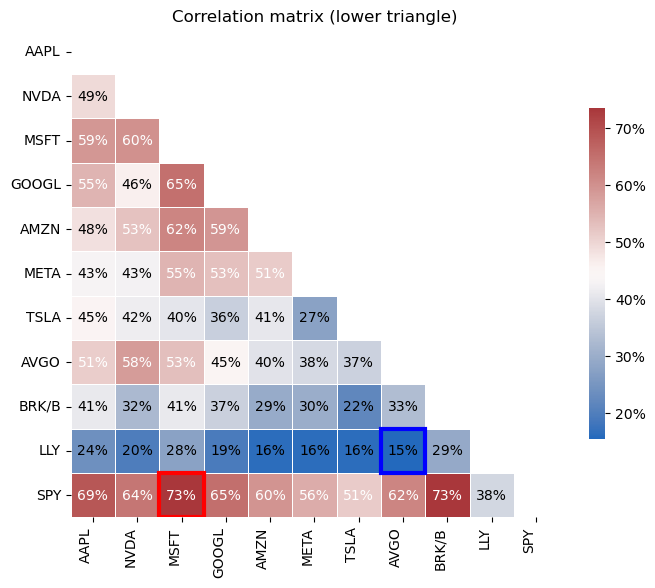

In [17]:
plot_corr_matrix(rets,triangle='lower',figsize=(7,7))

<Axes: >

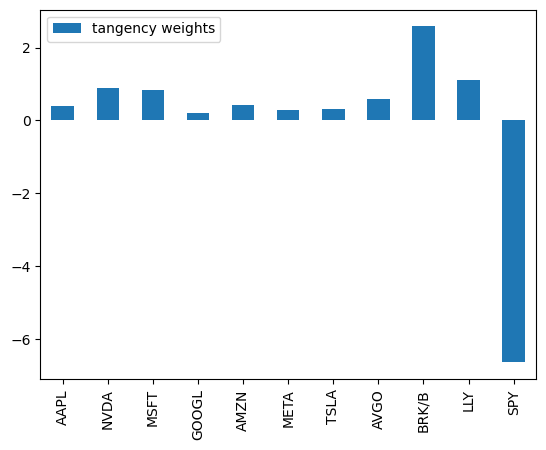

In [18]:
wts = pd.DataFrame(index=rets.columns)
wts['tangency weights'] = tangency_weights(rets)

# Plot the tangency weights as a bar chart
wts.plot.bar()

In [19]:
# Display the portfolio performance metrics
port = pd.DataFrame(rets @ wts['tangency weights'],columns=['tangency weights'])
performanceMetrics(port,annualization=FREQ).style.format('{:.2%}')

,Mean,Vol,Sharpe,Min,Max
tangency weights,130.22%,62.95%,206.85%,-27.41%,32.35%


The optimizer is **massively shorting SPY** because…
- it has lower mean return than the tech stocks (NVDA)
- it is highly correlated to the tech stocks and can offset much of their risk.

The optimizer is **massively long BRK**…
- even though BRK has the worst Sharpe ratio of the investments.
- But BRK is highly correlated to SPY while having relatively low correlation to tech. Thus it lowers total risk.

Report the following performance statistics of the portfolio achieved with the tangency weights calculated above.
- mean
- volatility
- Sharpe
(Annualize all three statistics.)

In [20]:
sharpe_vs_wts = pd.concat([wts['tangency weights'],mets['Sharpe']],axis=1)
# Display the weights sorted by tangency weights
sharpe_vs_wts.sort_values('tangency weights',ascending=False).style.format('{:.1%}')

,tangency weights,Sharpe
BRK/B,258.0%,70.8%
LLY,111.3%,99.5%
NVDA,88.3%,139.3%
MSFT,84.9%,108.9%
AVGO,60.2%,105.3%
AMZN,42.6%,95.9%
AAPL,40.9%,86.3%
TSLA,31.0%,80.1%
META,27.7%,74.6%
GOOGL,19.3%,77.5%


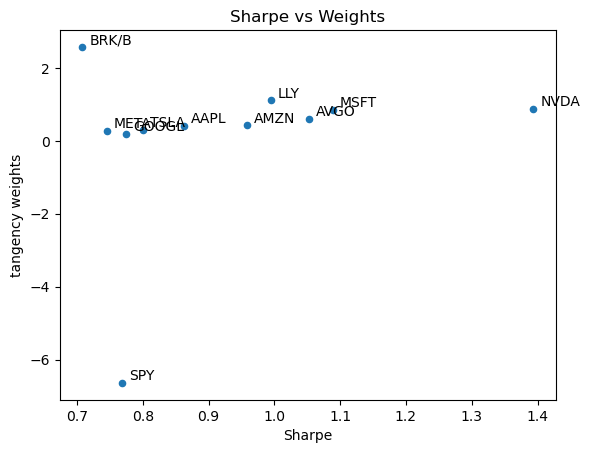

In [21]:
# Scatter plot of Sharpe vs tangency weights
sharpe_vs_wts.plot.scatter(x='Sharpe',y='tangency weights')

for idx in sharpe_vs_wts.index:
    x_value = sharpe_vs_wts.loc[idx, "Sharpe"]
    y_value = sharpe_vs_wts.loc[idx, "tangency weights"]
    
    plt.annotate(
        text=idx,               
        xy=(x_value, y_value),  
        xytext=(5, 2),          
        textcoords="offset points"
    )

plt.xlabel("Sharpe")
plt.ylabel("tangency weights")
plt.title("Sharpe vs Weights")
plt.show()

Continue working with the data above. Suppose we want to constrain the weights such that
- there are no short positions beyond negative $20 \%, w_i \geq-.20$ for all $i$
- none of the positions may have weight over $35 \%, w_i \leq .35$ for all $i$.
- all the asset weights must sum to 1

Furthermore,
- The targeted mean return is $20 \%$ per year.
- Be careful; the target is an annualized mean.

In [22]:
DO_EXCESS = True # whether to use excess returns
USE_RF_ZERO = True # whether to use zero risk-free rate

if USE_RF_ZERO:
    rf = 0
else:
    rf = bench['SHV'] # risk-free rate from SHV ETF, i.e. The iShares Short Treasury Bond ETF
# Get excess returns
retsx = rets.sub(rf) # subtract rf from each column

if DO_EXCESS:
    r = retsx
else:
    r = rets

# Calculate mean returns and covariance matrix
mean = r.mean() * FREQ
cov = r.cov() * FREQ
Nassets = r.shape[1] # number of assets

# Define bounds and target mean return
MINBOUND = -.10
MAXBOUND = .35
TARGET_MEAN = .20

In [23]:
# Define objective function: portfolio variance
def objective(w):        
    return (w.T @ cov @ w)

# Define equality constraints functions
def fun_constraint_capital(w):
    return np.sum(w) - 1

def fun_constraint_mean(w):
    return (mean @ w) - TARGET_MEAN

# Organize constraints into dictionary format
constraint_capital = {'type': 'eq', 'fun': fun_constraint_capital}
constraint_mean = {'type': 'eq', 'fun': fun_constraint_mean}

if DO_EXCESS:
    """
    when DO_EXCESS is True, we assume rf assets exists in our portfolio
    All weights (including the risk-free asset) need to sum to 1
    The weights for risky assets do not need to sum to 1 because the rf asset can take up the difference
    i.e 1'w + w_rf = 1, where w_rf is the weight of the risk-free asset
    - w_rf > 0 means we are lending at the risk-free rate to invest in risky assets
    - w_rf < 0 means we are borrowing at the risk-free rate to invest in risky assets
    """
    constraints = ([constraint_mean])
else:
    constraints = ([constraint_capital, constraint_mean])

# Create a DataFrame for bounds
bounds_df = pd.DataFrame(index=rets.columns,columns=['Min','Max'],dtype=float)
bounds_df['Min'] = MINBOUND
bounds_df['Max'] = MAXBOUND

# Store bounds as list of tuples for each asset
bounds = [tuple(bounds_df.iloc[i,:].values) for i in range(Nassets)]

In [24]:
# Prepare DataFrame to store optimal weights
wstar = pd.DataFrame(index=mets.index,columns=['bounded','unbounded'],dtype=float)

# Set optimization parameters
TOL = 1e-8
METHOD = 'SLSQP'
#METHOD = 'trust-constr'
w0 = np.ones(Nassets) / Nassets # Initial guess: equal weights

# Run quadratic programming optimization
solution_unbounded = minimize(objective, w0, method=METHOD, constraints=constraints, tol=TOL)
solution_bounded = minimize(objective, w0, method=METHOD, bounds=bounds, constraints=constraints, tol=TOL)
wstar['bounded'] = solution_bounded.x
wstar['unbounded'] = solution_unbounded.x

# Analytical solution from MV optimization for comparison to unbounded case
wstar['analytic'] = MVweights(mean=mean,cov=cov,isexcess=DO_EXCESS,target=TARGET_MEAN)

if solution_bounded.success and solution_unbounded.success:
    print('Optimization SUCCESSFUL.')
else:
    print('Optimization FAILED.')

print(f'Iterations: {solution_bounded.nit}.')

wstar.sort_values('bounded',ascending=False).style.format('{:.2%}')

Optimization SUCCESSFUL.
Iterations: 19.


,bounded,unbounded,analytic
LLY,19.03%,17.12%,17.09%
NVDA,15.30%,13.55%,13.56%
AVGO,6.30%,9.25%,9.24%
AMZN,5.80%,6.52%,6.55%
BRK/B,5.75%,39.63%,39.63%
MSFT,4.38%,13.04%,13.03%
TSLA,2.07%,4.76%,4.76%
META,0.66%,4.27%,4.26%
AAPL,-1.71%,6.29%,6.29%
GOOGL,-3.55%,2.98%,2.97%


In [ ]:
# Calculate and display performance metrics for optimized portfolios
optimized = pd.DataFrame(index=['bounded', 'unbounded', 'analytic'], columns=['mean','vol'],dtype=float)

optimized.loc['bounded','mean'] = wstar['bounded'] @ mean
optimized.loc['bounded','vol'] = np.sqrt(wstar['bounded'] @ cov @ wstar['bounded'])

optimized.loc['unbounded','mean'] = wstar['unbounded'] @ mean
optimized.loc['unbounded','vol'] = np.sqrt(wstar['unbounded'] @ cov @ wstar['unbounded'])

optimized.loc['analytic','mean'] = wstar['analytic'] @ mean
optimized.loc['analytic','vol'] = np.sqrt(wstar['analytic'] @ cov @ wstar['analytic'])

optimized['sharpe'] = optimized['mean'] / optimized['vol']

optimized.style.format('{:.2%}')

,mean,vol,sharpe
bounded,20.00%,11.92%,167.83%
unbounded,20.00%,9.67%,206.85%
analytic,20.00%,9.67%,206.85%


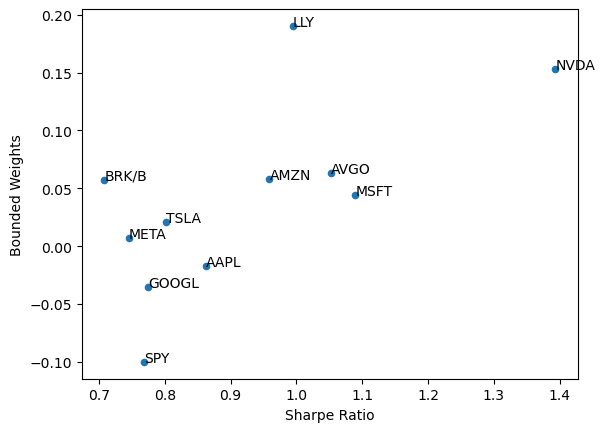

In [28]:
df = pd.concat([wstar[['bounded']],mets[['Sharpe']]],axis=1).sort_values('Sharpe',ascending=False)
ax = df.plot.scatter(x='Sharpe',y='bounded')
ax.set_xlabel('Sharpe Ratio')
ax.set_ylabel('Bounded Weights')
for idx, row in df.iterrows():
    ax.annotate(idx, (row['Sharpe'], row['bounded']))

In [ ]:
# Calculate Lagrange multipliers from the bounded optimization
TOL = 1e-12
METHOD = 'trust-constr'

w0 = wstar['bounded']
solutionALT = minimize(objective, w0, method=METHOD, bounds=bounds,constraints=constraints, tol=TOL)

pd.DataFrame(solutionALT.v[-1], index=mean.index, columns=['Lagrange Multipliers']).sort_values('Lagrange Multipliers',ascending=False).style.format('{:.2%}'.format)

,Lagrange Multipliers
AVGO,0.00%
TSLA,0.00%
MSFT,0.00%
GOOGL,-0.00%
LLY,-0.00%
BRK/B,-0.00%
NVDA,-0.00%
AAPL,-0.00%
AMZN,-0.00%
META,-0.00%


For each asset $i$, **Lagrange multipliers** tells you whether a bound is binding and which side:
- $\approx 0 \rightarrow$ weight is interior (neither min nor max is binding).
- $>0 \rightarrow$ the upper bound (e.g., MAXBOUND) is active; loosening that upper bound would lower the minimized variance at a rate of about the multiplier per unit relaxation.
- < $0 \rightarrow$ the lower bound (e.g., MINBOUND) is active; loosening (i.e., lowering) that lower bound would lower the minimized variance at a rate of about |multiplier| per unit relaxation.

## Chapter 2: Linear Factor Decomposition

### Replication View of Linar Factor Decomposition

#### Example: Replicating Regressions

Use the file, data/port_decomp_example.xlsx.

The data file contains...
- Return rates, $r_t^i$, for various asset classes, (via ETFs.)
- Most notable among these securities is SPY, the return on the S\&P 500. Denote this as $r_t^{\text {spy }}$.
- A separate tab gives return rates for a particular portfolio, $r_t^p$.

In [39]:
# Load data for portfolio decomposition example
INFILE = "data/port_decomp_example.xlsx"
info = pd.read_excel(INFILE,sheet_name='info').set_index('ticker')
info

,shortName,quoteType,currency,volume,totalAssets,longBusinessSummary
ticker,,,,,,
SPY,SPDR S&P 500,ETF,USD,50026094,572926853120,The trust seeks to achieve its investment obje...
EFA,iShares MSCI EAFE ETF,ETF,USD,7395415,60435103744,The fund generally will invest at least 80% of...
EEM,iShares MSCI Emerging Index Fun,ETF,USD,18043080,16526614528,The fund generally will invest at least 80% of...
PSP,Invesco Global Listed Private E,ETF,USD,21723,235239184,The fund generally will invest at least 90% of...
QAI,NYLI Hedge Multi-Strategy Track,ETF,USD,49670,687488448,"The fund is a ""fund of funds"" which means it i..."
HYG,iShares iBoxx $ High Yield Corp,ETF,USD,23767843,14188549120,The underlying index is a rules-based index co...
DBC,Invesco DB Commodity Index Trac,ETF,USD,465424,1206291584,The fund pursues its investment objective by i...
IYR,iShares U.S. Real Estate ETF,ETF,USD,3354686,3193291776,The fund seeks to track the investment results...
IEF,iShares 7-10 Year Treasury Bond,ETF,USD,7319141,34838351872,The underlying index measures the performance ...


In [ ]:
# Load the returns data on all ETFs
rets = pd.read_excel(INFILE,sheet_name='total returns').set_index('Date')
rets.tail()

,SPY,EFA,EEM,PSP,QAI,HYG,DBC,IYR,IEF,BWX,TIP,SHV
Date,,,,,,,,,,,,
2024-12-31,-0.024060,-0.029502,-0.016967,-0.051399,-0.015700,-0.007803,0.017227,-0.082892,-0.022584,-0.033754,-0.017144,0.004031
2025-01-31,0.026856,0.048009,0.021521,0.067995,0.016237,0.013605,0.027596,0.018913,0.006166,0.000935,0.013702,0.003633
2025-02-28,-0.012695,0.029531,0.011470,-0.040107,-0.005952,0.009703,0.001366,0.037861,0.027997,0.013991,0.021572,0.003115
2025-03-31,-0.055719,0.001839,0.011340,-0.060826,-0.013237,-0.010858,0.022727,-0.023382,0.003419,0.010353,0.006797,0.003343
2025-04-30,-0.009063,0.038174,-0.001144,-0.002497,-0.001916,0.006522,-0.068444,-0.024856,0.008983,0.057697,0.000082,0.003216


In [42]:
# Load the portfolio returns data
port =  pd.read_excel(INFILE,sheet_name='portfolio returns').set_index('Date')
port.tail()

,portfolio
Date,
2024-12-31,-0.043144
2025-01-31,0.027327
2025-02-28,0.004950
2025-03-31,-0.023506
2025-04-30,-0.005072


##### 1. Single Factor Exposure

Estimate the regression of the portfolio return on SPY

$$
r_t^p=\alpha+\beta r_t^{\mathrm{spy}}+\epsilon_t^{p, \mathrm{spy}}
$$

Specifically, report your estimates of alpha, beta, and the r-squared.

In [43]:
X = sm.add_constant(rets['SPY'])
y = port
mod = sm.OLS(y, X).fit()
mod.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              portfolio   R-squared:                       0.757
Model:                            OLS   Adj. R-squared:                  0.755
Method:                 Least Squares   F-statistic:                     566.2
Date:                Mon, 20 Oct 2025   Prob (F-statistic):           9.12e-58
Time:                        16:27:29   Log-Likelihood:                 513.29
No. Observations:                 184   AIC:                            -1023.
Df Residuals:                     182   BIC:                            -1016.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0017      0.001     -1.451      0.149      -0.004       0.001
SPY            0.6270      0.026     23.796      0.000       0.575       0.679
==============================================================================
Omnibus:                        2.378   Durbin-Watson:                   2.026
Prob(Omnibus):                  0.305   Jarque-Bera (JB):                2.152
Skew:                           0.110   Prob(JB):                        0.341
Kurtosis:                       3.482   Cond. No.                         23.9
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

##### 2. Multi-factor Exposure

Estimate the regression of the portfolio return on SPY and on HYG, the return on high-yield corporate bonds, denoted as $r_t^{\text {hyg}}$:

$$
r_t^p=\alpha+\beta^{\mathrm{spy}} r_t^{\mathrm{spy}}+\beta^{\mathrm{hyg}} r_t^{\mathrm{hyg}}+\epsilon_t
$$


Specifically, report your estimates of alpha, the betas, and the r-squared.

Note that the parameters (such as $\beta^{\text {spy}}$ ) in this multivariate model are not the same as used in the univariate model of part 1.

In [44]:
X = sm.add_constant(rets[['SPY', 'HYG']])
y = port
mod_multi = sm.OLS(y, X).fit()
mod_multi.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              portfolio   R-squared:                       0.823
Model:                            OLS   Adj. R-squared:                  0.821
Method:                 Least Squares   F-statistic:                     419.4
Date:                Mon, 20 Oct 2025   Prob (F-statistic):           1.13e-68
Time:                        16:28:42   Log-Likelihood:                 542.28
No. Observations:                 184   AIC:                            -1079.
Df Residuals:                     181   BIC:                            -1069.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0015      0.001     -1.526      0.129      -0.003       0.000
SPY            0.3826      0.037     10.221      0.000       0.309       0.456
HYG            0.5766      0.070      8.187      0.000       0.438       0.716
==============================================================================
Omnibus:                        0.549   Durbin-Watson:                   2.282
Prob(Omnibus):                  0.760   Jarque-Bera (JB):                0.519
Skew:                           0.128   Prob(JB):                        0.772
Kurtosis:                       2.954   Cond. No.                         81.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

##### 3. Replication Values

Calculate the series of fitted regression values, sometimes referred to as $\hat{y}$ in standard textbooks:

$$
\hat{r}_t^p=\hat{\alpha}+\hat{\beta}^{\text {spy}} r_t^{\text {spy}}+\hat{\beta}^{\text {hyg}} r_t^{\text {hyg }}
$$


Your statistical package will output these fitted values for you, or you can construct them using the estimated parameters.

How does this compare to the $r$-squared of the regression in problem 2 ?

In [46]:
corr_port_multi = port.corrwith(mod_multi.fittedvalues).iloc[0]
print(f'Correlation between portfolio and replication: {corr_port_multi:.2%}.')
print(f'Square of this correaltion is {corr_port_multi**2:.2%}\nwhich equals the R-squared.')

Correlation between portfolio and replication: 90.69%.
Square of this correaltion is 82.25%
which equals the R-squared.


##### 4. Uni vs Multi

How do the SPY betas differ across the univariate and multivariate models? How does this relate to the correlation between $r^{\text {spy}}$ and $r^{\text {hyg}}$ ?

In [47]:
TICKreg1 = 'SPY'
TICKreg2 = 'HYG'
corrREGS = rets[TICKreg2].corr(rets[TICKreg1])
print(f'Correlation between {TICKreg1} and {TICKreg2} is {corrREGS:.1%}')

Correlation between SPY and HYG is 79.8%


The beta for SPY in (2) is much smaller than in (1). This is because HYG and SPY are significantly correlated, therefore a large proportion of the variation in the Portfolio return which was being attributed to SPY (in eq 1) was actually better explained by HYG. Thus, in eq (2) this gets attributed more directly to HYG, and less is attributed to SPY.

##### 5. Decompose portfolio holdings

The portfolio return, $r_t^p$, is a combination of the base assets that are provided here. Use linear regression to uncover which weights were used in constructing the portfolio.

$$
r_t^p=\alpha+(\boldsymbol{\beta})^{\prime} \boldsymbol{r}_t+\epsilon_t
$$

where $\boldsymbol{r}$ denotes the vector of returns for the individual securities.
-What does the regression find were the original weights?
- How precise is the estimation? Consider the R-squared and t-stats.

Feel free to include an $\alpha$ in this model, even though you know the portfolio is an exact function of the individual securities. The estimation should find $\alpha$ of (nearly) zero.

In [48]:
X = sm.add_constant(rets)
y = port
mod_exact = sm.OLS(y, X).fit()
display(mod_exact.params.to_frame().rename(columns={0:'weights'}).sort_values('weights',ascending=False).T.style.format('{:.2f}'))
mod_exact.summary()

,QAI,IEF,PSP,IYR,const,HYG,SHV,TIP,BWX,DBC,SPY,EFA,EEM
weights,0.25,0.25,0.25,0.25,0.00,0.00,0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              portfolio   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 1.797e+29
Date:                Mon, 20 Oct 2025   Prob (F-statistic):               0.00
Time:                        16:41:21   Log-Likelihood:                 6336.0
No. Observations:                 184   AIC:                        -1.265e+04
Df Residuals:                     171   BIC:                        -1.260e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       2.027e-16   2.67e-17      7.601      0.000     1.5e-16    2.55e-16
SPY        -9.021e-16   1.39e-15     -0.649      0.517   -3.65e-15    1.84e-15
EFA        -9.125e-16   1.34e-15     -0.683      0.496   -3.55e-15    1.72e-15
EEM        -9.576e-16   8.04e-16     -1.192      0.235   -2.54e-15    6.29e-16
PSP            0.2500   9.92e-16   2.52e+14      0.000       0.250       0.250
QAI            0.2500   3.68e-15   6.79e+13      0.000       0.250       0.250
HYG                 0   1.95e-15          0      1.000   -3.85e-15    3.85e-15
DBC        -4.649e-16   6.08e-16     -0.764      0.446   -1.67e-15    7.36e-16
IYR            0.2500   7.89e-16   3.17e+14      0.000       0.250       0.250
IEF            0.2500   2.54e-15   9.84e+13      0.000       0.250       0.250
BWX        -2.914e-16   1.64e-15     -0.177      0.859   -3.53e-15    2.95e-15
TIP         -1.11e-16   2.82e-15     -0.039      0.969   -5.68e-15    5.46e-15
SHV                 0   1.41e-14          0      1.000   -2.77e-14    2.77e-14
==============================================================================
Omnibus:                       18.762   Durbin-Watson:                   1.297
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               33.209
Skew:                          -0.523   Prob(JB):                     6.15e-08
Kurtosis:                       4.800   Cond. No.                         686.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

##### 6. Replicate an asset

Suppose that we want to mimic a return, EEM using the other returns. Run the following regression-but do so only using data through the end of 2022 .

$$
r_t^{E E M}=\alpha+\left(\boldsymbol{\beta}^{\boldsymbol{r}}\right)^{\prime} \boldsymbol{r}_t+\epsilon_t
$$

where $\boldsymbol{r}$ denotes the vector of returns for the other securities, excluding the target, EEM.
(a)

Report the r-squared and the estimate of the vector, $\boldsymbol{\beta}$.
(b)

Report the t -stats of the explanatory returns. Which have absolute value greater than 2 ?
(c)

Plot the returns of EEM along with the replication values.

In [49]:
T1 = '2022'
T2 = '2023'
TICKrep = 'EEM'

rets_IS = rets.loc[:T1,:]

X = sm.add_constant(rets_IS.drop(columns=TICKrep))
y = rets_IS[[TICKrep]]
mod_replicate = sm.OLS(y, X).fit()
mod_replicate.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    EEM   R-squared:                       0.768
Model:                            OLS   Adj. R-squared:                  0.750
Method:                 Least Squares   F-statistic:                     43.24
Date:                Mon, 20 Oct 2025   Prob (F-statistic):           3.73e-40
Time:                        16:41:58   Log-Likelihood:                 348.19
No. Observations:                 156   AIC:                            -672.4
Df Residuals:                     144   BIC:                            -635.8
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0014      0.003      0.521      0.603      -0.004       0.007
SPY           -0.2393      0.154     -1.555      0.122      -0.543       0.065
EFA            0.5338      0.145      3.672      0.000       0.246       0.821
PSP            0.0037      0.119      0.031      0.975      -0.232       0.240
QAI            1.1292      0.375      3.015      0.003       0.389       1.870
HYG           -0.0069      0.194     -0.036      0.972      -0.391       0.377
DBC            0.0212      0.062      0.340      0.734      -0.102       0.145
IYR            0.0785      0.082      0.953      0.342      -0.084       0.241
IEF           -0.8116      0.272     -2.988      0.003      -1.349      -0.275
BWX            0.5937      0.169      3.504      0.001       0.259       0.929
TIP            0.2940      0.295      0.997      0.321      -0.289       0.877
SHV            0.6187      2.745      0.225      0.822      -4.807       6.044
==============================================================================
Omnibus:                        0.066   Durbin-Watson:                   2.334
Prob(Omnibus):                  0.967   Jarque-Bera (JB):                0.209
Skew:                           0.005   Prob(JB):                        0.901
Kurtosis:                       2.821   Cond. No.                     1.27e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.27e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

Note that while we can estimate an **R-squared**, it doesn’t make much sense in a regression without an intercept. 

It does not need to be between 0 and 1.

The stats-models Python package puts a “Note” at the bottom of the table above reminding users of that fact.

In [51]:
# Report the t-stats in descending order
mod_replicate.tvalues.sort_values(ascending=False).to_frame().rename(columns={0:'t-stats'}).T.style.format('{:.1f}')

,EFA,BWX,QAI,TIP,IYR,const,DBC,SHV,PSP,HYG,SPY,IEF
t-stats,3.7,3.5,3.0,1.0,1.0,0.5,0.3,0.2,0.0,-0.0,-1.6,-3.0


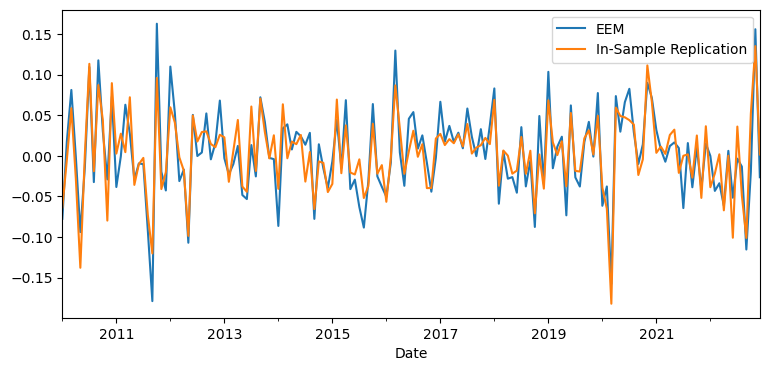

In [ ]:
# Plot in-sample replication
pd.concat([y, mod_replicate.fittedvalues.rename('In-Sample Replication')], axis=1).plot(figsize=(9, 4))
plt.show()

##### 6. Out-of-Sample Fit

Perhaps the replication results in the previous problem are overstated given that they estimated the parameters within a sample and then evaluated how well the result fit in the same sample. This is known as in-sample fit.

Using the estimates through 2022, (the $\alpha$ and $\beta^{\wedge}$ from the previous problem,) calculate the out-of-sample (OOS) values of the replication, using the 2023-2024 returns, denoted $\boldsymbol{r}_t^{\text {oos }}$ :

$$
\hat{\boldsymbol{r}}_t^{E E M}=\left(\widehat{\boldsymbol{\beta}}^{\boldsymbol{r}}\right)^{\prime} \boldsymbol{r}_t^{\mathrm{oos}}
$$

(a)

What is the correlation between $\hat{r}_t^{E E M}$ and $\boldsymbol{r}_t^{\text {oos }}$ ?
(b)

How does this compare to the r-squared from the regression above based on in-sample data, (through 2022 ?)

In [60]:
# Run in-sample regression
reg = LinearRegression(fit_intercept=True).fit(X,y)
fit_comp_IS = pd.concat([y,pd.DataFrame(reg.predict(X),index=y.index)],axis=1).rename(columns={0:'IS'})
corr_IS = fit_comp_IS.corr().iloc[0,1]

# Run out-of-sample replication
rets_OOS = rets.loc[T2:,:]
X = sm.add_constant(rets_OOS.drop(columns=TICKrep))
y = rets_OOS[[TICKrep]]

fit_comp_OOS = pd.concat([y,pd.DataFrame(reg.predict(X),index=y.index)],axis=1).rename(columns={0:'OOS'})
corr_OOS = fit_comp_OOS.corr().iloc[0,1]

# Correlation between actual and replicating portfolio: in-sample and out-of-sample
print(f'Correlation between {TICKrep} and Replicating Portfolio')
print(f'In-Sample: {corr_IS:.1%}')
print(f'Out-of-Sample: {corr_OOS:.1%}')

Correlation between EEM and Replicating Portfolio
In-Sample: 89.0%
Out-of-Sample: 89.0%


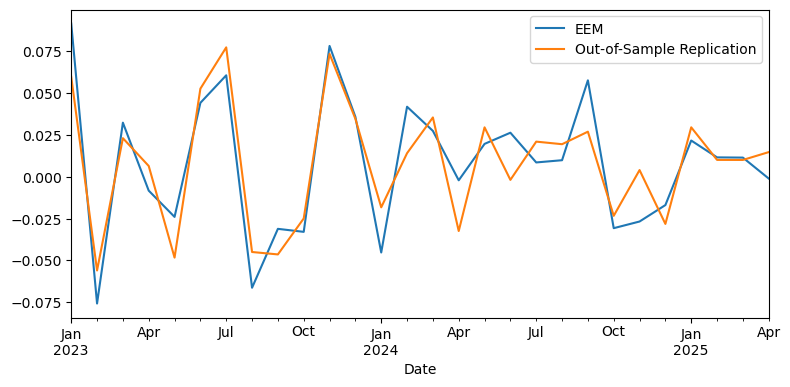

In [64]:
# Plot out-of-sample replication
fit_comp_OOS.rename(columns={'OOS':'Out-of-Sample Replication'}).plot(figsize=(9, 4))
plt.show()

## Chapter 3: Dynamics

### 3.1 Value at Risk (VaR)

#### Example: S&P500 Components
This problem uses weekly return data from data/spx_returns_weekly.xlsx.

Choose any 4 stocks to evaluate below.

For example,
- AAPL
- META
- NVDA
- TSLA

In [ ]:
# Load data for volatility, mean, and VaR calculations
LOADFILE = 'data/spx_returns_weekly.xlsx'
TICKS = [
    'AAPL',
    'META',
    'NVDA',
    'TSLA'
    ]

FREQ = 52 # weekly frequency
WINDOW = 26 # rolling window size

QUANTILE = .05 # quantile for VaR calculation
mu = 0 # mean return approximation

# Load returns data
SHEET = 's&p500 rets'
rets = pd.read_excel(LOADFILE,sheet_name=SHEET).set_index('date')
rets = rets[TICKS]
rets.dropna(inplace=True)

##### 1 Diversification
Using the full sample, calculate for each series the (unconditional)
- volatility
- empirical VaR (.05)
- empirical CVaR (.05)

Recall that by empirical we refer to the direct quantile estimation. (For example, using .quantile() in pandas.

Also Form an equally-weighted portfolio of the investments.

Calculate the statistics for this portfolio, and compare the results to the individual return statistics. What do you find? What is driving this result?

Re-calculate the statistics for this portfolio, but this time drop your most volatile asset, and replace the portion it was getting with 0. (You could imagine we're replacing the most volatile asset with a negligibly small risk-free rate.)

How much risk is your most volatile asset adding to the portfolio? Is this in line with the amount of risk we measured in the stand-alone risk-assessment of that asset?

In [70]:
ANNUALIZE = np.sqrt(252)

rtab = rets.copy()

# Get the ticker with the maximum volatility
TICK_MAX_VOL = rets.std().idxmax()

# Calculate portfolio and stand-alone returns
rtab['eq-wtd portfolio'] = rtab.mean(axis=1) # equally-weighted portfolio
rtab[f'eq-wtd portfolio-ex {TICK_MAX_VOL}'] = rtab.drop(columns=[TICK_MAX_VOL]).mean(axis=1)
rtab[f'stand-alone {TICK_MAX_VOL}'] = rtab[[TICK_MAX_VOL]]

# Calculate risk metrics: volatility, VaR, and CVaR
risk0 = pd.DataFrame(index=['vol'],columns=rtab.columns,dtype=float)
risk0.loc['vol'] = rtab.std() * ANNUALIZE
risk0.loc[f'VaR {QUANTILE}'] = rtab.quantile(QUANTILE)
risk0.loc[f'CVaR {QUANTILE}'] = rtab[rtab<rtab.quantile(QUANTILE)].mean()

risk0.style.format('{:.2%}')

,AAPL,META,NVDA,TSLA,eq-wtd portfolio,eq-wtd portfolio-ex TSLA,stand-alone TSLA
vol,60.90%,77.34%,101.99%,129.10%,69.46%,64.31%,129.10%
VaR 0.05,-5.64%,-7.00%,-8.69%,-11.74%,-6.19%,-5.58%,-11.74%
CVaR 0.05,-8.31%,-10.32%,-11.65%,-14.78%,-8.50%,-8.06%,-14.78%


**Subadditivity: σ yes, VaR not guaranteed**

**Volatility (σ)** is subadditive.  
Equal-weighted portfolio σ = **69.46%**, far below the average of individual σ’s  
(¼·(60.90 + 77.34 + 101.99 + 129.10) = **92.33%**).  
Diversification ↓ σ because correlations < 1.

**VaR** isn’t guaranteed to be subadditive (only under special distributions).  
In your sample it still diversifies overall —  
portfolio |VaR₅%| = **6.19%** < ¼·(5.64 + 7.00 + 8.69 + 11.74) = **8.27%** —  
but adding **TSLA** worsens the tail versus the 3-stock mix (|VaR| goes 5.58% → 6.19%).  
That’s the “**VaR not guaranteed**” idea showing up as **disproportionate tail sensitivity to TSLA**.


##### 2.1

Let's measure the conditional statistics of the equally-weighted portfolio, as of the end of the sample.

**Volatility**

For each security, calculate the rolling volatility series, $\sigma_t$, with a window of $m=26$. The value at $\sigma_t$ in the notes denotes the estimate using data through time $t-1$, and thus (potentially) predicting the volatility at $\sigma_t$.

$$
\sigma_t^2=\frac{1}{m} \sum_{i=1}^m r_{t-i}^2
$$

**Mean**

Suppose we can approximate that the daily mean return is zero.

**VaR**

Calculate the normal VaR and normal CVaR for $q=.05$ and $\tau=1$ as of the end of the sample.Use the approximation, $\mathrm{z}_{.05}=-1.65$.

**Notation Note**
In this setup, we are using a forecasted volatility, $\sigma_t$ to estimate the VaR return we would have estimated at the end of $t-1$ in prediction of time $t$.

**Conclude and Compare**

Report
- volatility (annualized).
- normal VaR (.05)
- normal CVaR (.05)

How do these compare to the answers before?

<Axes: xlabel='date'>

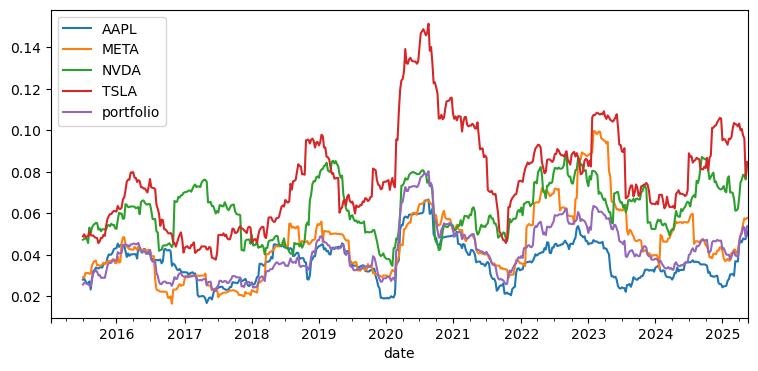

In [75]:
method = 'rolling'

rets['portfolio'] = rets.mean(axis=1)

if method == 'rolling':
    sigma = rets.rolling(WINDOW).std()
elif method == 'expanding':
    sigma = rets.expanding(WINDOW).std()

# plot the rolling volatility
sigma.plot(figsize=(9, 4))

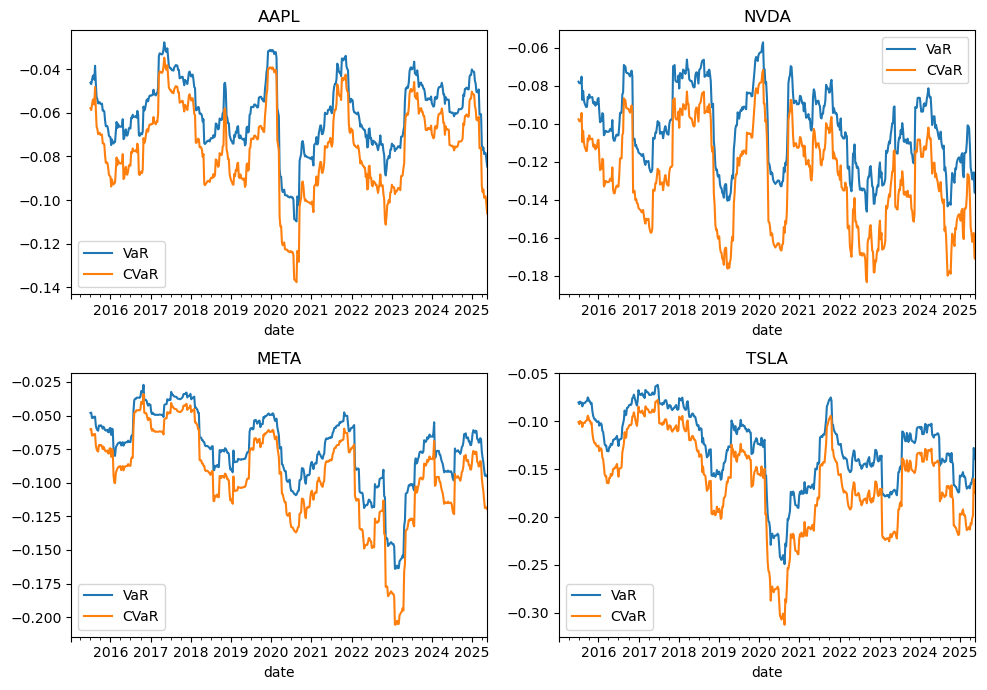

In [83]:
from scipy.stats import norm
zscore = norm.ppf(QUANTILE)
phi = norm.pdf(zscore)

VaRret = mu + zscore * sigma
CVaRret = mu - phi / QUANTILE * sigma

# Plot VaR and CVaR time series
fig, ax = plt.subplots(2,2,figsize=(10,7))
for i,tick in enumerate(TICKS):
    VaRret[tick].plot(ax=ax[i%2,int(np.floor(i/2))],title=f'{tick}', label='VaR')
    CVaRret[tick].plot(ax=ax[i%2,int(np.floor(i/2))],title=f'{tick}', label='CVaR')
    ax[i%2,int(np.floor(i/2))].legend()
plt.tight_layout()

In [ ]:
# Compare unconditional (all historical data) and conditional (conditional on the last observation) risk measures
tabcomp = risk0.iloc[1,:-2].to_frame('unconditional').join(VaRret.iloc[-1,:].to_frame('conditional'))
tabcvar = risk0.iloc[2,:-2].to_frame('unconditional').join(CVaRret.iloc[-1,:].to_frame('conditional'))
tabcomp = pd.concat([tabcomp,tabcvar],keys=['VaR','CVaR'],axis=1)
tabcomp.style.format('{:.1%}')

##### 2.2

Backtest the VaR using the hit test. Namely, check how many times the realized return at $t$ was smaller than the VaR return calculated using $\sigma_{t_1}$ (where again remember the notation in the notes uses $\sigma_t$ as a vol based on data through $t-1$.)

Report the percentage of "hits" using both the
- expanding volatility
- rolling volatility

In [ ]:
hits = rets < VaRret.shift() # identify hits where actual return is less than VaR

# Calculate and display hit ratio
(hits.sum()/hits.shape[0]).to_frame('Hit Ratio').style.format('{:.2%}')

,Hit Ratio
AAPL,4.98%
META,4.24%
NVDA,4.24%
TSLA,4.98%
portfolio,4.06%
